In [1]:
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.colors import LogNorm
from numba import njit

from shared.common import jump_prob, load_config, plot_setup, save_figure

In [2]:
settings = load_config()
config = settings['coast']
out = Path('../output')
shape = tuple(config['shape'])
nx, ny, nz = shape
dx, dy, dz = config['spacing_m']
cell_volume = dx*dy*dz
dt, duration = config['step_s'], config['duration_s']
times = np.arange(dt/2, duration, dt)
snapshot_times = config['snapshot_s']
Kx, Ky, Kz = config['diffusivity_m2_s']
species = ['CO₂-C', 'VOC-C', 'Aerosol-C']
regions = ['Mountain', 'Rural', 'Suburban', 'Urban', 'Ocean']
scenario_specs = [
    ('Full', True, True, True, True, True), ('Flat', False, True, True, True, True),
    ('Fixed wind', True, False, True, True, True), ('Fixed emissions', True, True, False, True, True),
    ('No surface exchange', True, True, True, False, True), ('No reaction', True, True, True, True, False),
]
palette = plot_setup()

In [3]:
rng = np.random.default_rng(settings['seed'])
ix, iy = np.indices(shape[:2])
region = np.broadcast_to(np.digitize(np.arange(nx), [19, 29, 37, 49])[:, None], (nx, ny))
ridge_center = 13 + 2*np.sin(iy/4.5)
ridge_height = 30 + 203*(1 - 0.62*np.exp(-0.5*((iy - 14)/2.6)**2))
elevation = ridge_height * np.exp(-0.5*((ix - ridge_center)/2.9)**2)
terrain = np.floor(elevation/dz + 0.5).astype(int)
for bx in [38, 42, 46]:
    for by in [4, 10, 16, 23, 27]:
        terrain[bx:bx+2, by:by+2] += rng.integers(1, 4)

offsets = np.array(list(product([-1, 0, 1], repeat=3)), dtype=np.int64)
paths = []
for offset in offsets:
    choices = [[0] if d == 0 else [0, d] for d in offset]
    paths.append([point for point in product(*choices) if any(point)])
moves = np.zeros((27, 7, 3), dtype=np.int64)
path_lengths = np.array([len(path) for path in paths])
for i, path in enumerate(paths):
    moves[i, :len(path)] = np.array(path, dtype=np.int64).reshape(-1, 3)

In [4]:
@njit
def build_routes(floor, nz, offsets, moves, path_lengths):
    nx, ny = floor.shape
    routes = np.full((nx*ny*nz, len(offsets)), -1, dtype=np.int32)
    active = np.empty(nx*ny*nz, dtype=np.int32)
    count = 0
    for i in range(nx):
        for j in range(ny):
            for k in range(floor[i, j], nz):
                start = (i*ny + j)*nz + k
                active[count] = start
                count += 1
                for m in range(len(offsets)):
                    blocked = False
                    # check faces/edges as well as the diagonal endpoint
                    for s in range(path_lengths[m]):
                        ii = i + moves[m, s, 0]
                        jj = j + moves[m, s, 1]
                        kk = max(0, k + moves[m, s, 2])
                        if 0 <= ii < nx and 0 <= jj < ny and kk < floor[ii, jj]:
                            blocked = True
                            break
                    if blocked:
                        routes[start, m] = start
                    else:
                        ii = i + offsets[m, 0]
                        jj = j + offsets[m, 1]
                        kk = max(0, k + offsets[m, 2])
                        if 0 <= ii < nx and 0 <= jj < ny and kk < nz:
                            routes[start, m] = (ii*ny + jj)*nz + kk
    return routes, active[:count]


@njit
def move_air(air, next_air, routes, active, px, py, pz):
    next_air.fill(0)
    exported = np.zeros(3)
    for i in active:
        for a in range(3):
            for b in range(3):
                horizontal = px[i, a]*py[i, b]
                for c in range(3):
                    weight = horizontal*pz[c]
                    j = routes[i, a*9 + b*3 + c]
                    if j < 0:
                        for s in range(3):
                            exported[s] += weight*air[i, s]
                    else:
                        for s in range(3):
                            next_air[j, s] += weight*air[i, s]
    return exported

In [5]:
def source_fields(floor):
    templates = [(5, 14, 1.3, 2.2, 1), (23, 12, 2.6, 4, 0),
                 (32, 17, 2, 3, 1), (43, 15, 2.3, 4, 2)]
    footprints = np.zeros((len(templates), np.prod(shape)))
    for n, (cx, cy, wx, wy, above) in enumerate(templates):
        spatial = np.exp(-0.5*((ix-cx)/wx)**2 - 0.5*((iy-cy)/wy)**2) * (region == n)
        cells = np.ravel_multi_index((ix, iy, floor + above), shape)
        footprints[n, cells.ravel()] = spatial.ravel()/spatial.sum()
    return footprints


urban_peak = 0.12 + 0.23*np.exp(-0.5*((times-2300)/580)**2) + 0.12*np.exp(-0.5*((times-6250)/800)**2)
pulse = 0.13 + 0.05*np.sin(2*np.pi*times/4100)
emissions = np.zeros((len(times), 4, 3))
emissions[:, :, 0] = np.column_stack([pulse, np.full_like(times, 0.028), np.full_like(times, 0.063), urban_peak])
emissions[:, 2, 1] = 0.013
emissions[:, 3, 1] = 0.23*urban_peak
emissions[:, 3, 2] = 0.035*urban_peak

base_wind = np.column_stack([2.04 + 0.63*np.sin(2*np.pi*(times-350)/5300),
                             0.47*np.sin(2*np.pi*(times-700)/4400)])
zone_speed = np.array([0.87, 1.05, 0.94, 0.80, 1.16])[region]
height_gain = 1 + 0.16*np.tanh(np.arange(nz)/5)
light = 0.65 + 0.35*np.sin(np.pi*times/duration)
photo_fraction = -np.expm1(-dt*light/config['voc_lifetime_s'])
pz = jump_prob(0, Kz, dz, dt)
crosswind = 0.10*np.sin((iy.ravel().repeat(nz)-ny/2)/8)

In [6]:
def simulate(floor, varying_wind, varying_emissions, exchange, react):
    routes, active = build_routes(floor, nz, offsets, moves, path_lengths)
    base = np.ravel_multi_index((ix, iy, floor), shape).ravel()
    zone = region.ravel()
    c_sink = -np.expm1(-dt*np.asarray(config['co2_uptake_m_s'])[zone]/dz)*exchange
    p_sink = -np.expm1(-dt*np.asarray(config['particle_uptake_m_s'])[zone]/dz)*exchange
    k_return = np.asarray(config['surface_return_s_inv'])[zone]
    k_store = np.asarray(config['surface_storage_s_inv'])[zone]
    turnover = -np.expm1(-dt*(k_return+k_store))*exchange
    store_fraction = k_store/(k_store+k_return)

    footprint = source_fields(floor)
    source_steps = emissions if varying_emissions else np.broadcast_to(emissions.mean(axis=0), emissions.shape)
    wind_steps = base_wind if varying_wind else np.broadcast_to(base_wind.mean(axis=0), base_wind.shape)
    ground_factor = np.broadcast_to(zone_speed[:, :, None]*height_gain, shape).ravel()
    # same spatial wind forcing for Flat; only solids and source AGL change
    valid_x = jump_prob(wind_steps[:, 0].max()*ground_factor.max(), Kx, dx, dt)
    valid_y = jump_prob(np.abs(wind_steps[:, 1]).max() + np.abs(crosswind).max(), Ky, dy, dt)
    assert min(valid_x.min(), valid_y.min(), pz.min()) >= 0
    air = np.zeros((np.prod(shape), 3))
    next_air = np.empty_like(air)
    surface, stored = np.zeros(nx*ny), np.zeros(nx*ny)
    emitted, escaped = np.zeros(3), np.zeros(3)
    converted = 0.0
    by_time, states = [], {}
    for t, (source, wind) in enumerate(zip(source_steps, wind_steps)):
        addition = dt*source
        air += footprint.T @ addition
        emitted += addition.sum(axis=0)

        # local VOC-C -> aerosol-C conversion, then synchronous transport
        reacted = air[:, 1]*(photo_fraction[t] if react else 0)
        air[:, 1] -= reacted
        air[:, 2] += reacted
        converted += reacted.sum()
        px = jump_prob(wind[0]*ground_factor, Kx, dx, dt)
        py = jump_prob(wind[1] + crosswind, Ky, dy, dt)
        escaped += move_air(air, next_air, routes, active, px, py, pz)
        air, next_air = next_air, air

        # first-layer sink and competition between return and long-lived storage
        co2 = air[base, 0]*c_sink
        particle = air[base, 2]*p_sink
        air[base, 0] -= co2
        air[base, 2] -= particle
        outgoing = surface*turnover
        burial = outgoing*store_fraction
        air[base, 0] += outgoing-burial
        surface += co2 + particle - outgoing
        stored += burial

        elapsed = (t+1)*dt
        live = air.sum(axis=0)
        ledger = live.sum() + surface.sum() + stored.sum() + escaped.sum()
        by_time.append([elapsed, *emitted, *live, surface[zone != 4].sum(),
                        surface[zone == 4].sum(), stored.sum(), escaped.sum(), converted, ledger-emitted.sum()])
        if elapsed in snapshot_times:
            states[elapsed] = (air.reshape(*shape, 3).copy(), surface.reshape(nx, ny).copy(), stored.reshape(nx, ny).copy())
    solid = np.arange(nz)[None, None, :] < floor[:, :, None]
    assert np.all(air.reshape(*shape, 3)[solid] == 0) and air.min() >= -1e-12
    return by_time, states

In [7]:
columns = ['time_s', 'emitted_co2_kg_c', 'emitted_voc_kg_c', 'emitted_aerosol_kg_c',
           'air_co2_kg_c', 'air_voc_kg_c', 'air_aerosol_kg_c', 'land_kg_c', 'ocean_kg_c',
           'stored_kg_c', 'escaped_kg_c', 'reacted_kg_c', 'balance_error_kg_c']
histories, snapshots = [], {}
flat = np.zeros_like(terrain)
for name, obstacles, varying_wind, varying_emissions, exchange, react in scenario_specs:
    history, states = simulate(terrain if obstacles else flat, varying_wind, varying_emissions, exchange, react)
    histories.append(pd.DataFrame(history, columns=columns).assign(scenario=name))
    snapshots[name] = states
history = pd.concat(histories, ignore_index=True)
history['emitted_total_kg_c'] = history[columns[1:4]].sum(axis=1)
history['air_total_kg_c'] = history[columns[4:7]].sum(axis=1)
summary = history.query('time_s == @duration').set_index('scenario').drop(columns='time_s')
summary['max_balance_abs_kg_c'] = history.groupby('scenario')['balance_error_kg_c'].apply(lambda e: e.abs().max())
assert summary['max_balance_abs_kg_c'].max() < 1e-8*summary['emitted_total_kg_c'].min()
assert np.allclose(summary['emitted_total_kg_c'], summary.loc['Full', 'emitted_total_kg_c'])
assert summary.loc['No reaction', 'reacted_kg_c'] == 0 < summary.loc['Full', 'reacted_kg_c']
assert summary.loc['No surface exchange', ['land_kg_c', 'ocean_kg_c', 'stored_kg_c']].sum() == 0
history.to_csv(out / 'carbon_ledger.csv', index=False)
summary.to_csv(out / 'scenario_summary.csv')
display(summary[['emitted_total_kg_c', 'air_total_kg_c', 'land_kg_c', 'ocean_kg_c',
                 'stored_kg_c', 'escaped_kg_c', 'reacted_kg_c', 'max_balance_abs_kg_c']].round(5))

,emitted_total_kg_c,air_total_kg_c,land_kg_c,ocean_kg_c,stored_kg_c,escaped_kg_c,reacted_kg_c,max_balance_abs_kg_c
scenario,,,,,,,,
Full,4221.0948,678.60127,24.96074,20.41784,8.38441,3488.73054,158.02174,0.0
Flat,4221.0948,571.57473,21.53700,25.11621,9.44155,3593.42531,155.41769,0.0
Fixed wind,4221.0948,699.66968,25.03926,20.91447,8.42983,3467.04156,159.18334,0.0
Fixed emissions,4221.0948,783.47967,25.62624,20.17317,8.07887,3383.73686,156.49877,0.0
No surface exchange,4221.0948,683.35080,0.00000,0.00000,0.00000,3537.74400,158.02174,0.0
No reaction,4221.0948,678.65255,23.67363,19.69315,8.03798,3491.03749,0.00000,0.0


In [8]:
names = [spec[0] for spec in scenario_specs]
np.savez_compressed(out / 'carbon_states.npz', time_s=np.asarray(snapshot_times), terrain_cells=terrain,
                    zone=region, scenario=np.asarray(names), species=np.asarray(species),
                    air_kg_c=np.array([[snapshots[name][t][0] for t in snapshot_times] for name in names]),
                    surface_kg_c=np.array([[snapshots[name][t][1] for t in snapshot_times] for name in names]),
                    stored_kg_c=np.array([[snapshots[name][t][2] for t in snapshot_times] for name in names]))
forcing = pd.DataFrame({'time_s': times, 'wind_u_m_s': base_wind[:, 0], 'wind_v_m_s': base_wind[:, 1],
                        'urban_co2_kg_c_s': emissions[:, 3, 0], 'urban_voc_kg_c_s': emissions[:, 3, 1],
                        'windward_co2_kg_c_s': emissions[:, 0, 0]})
forcing.to_csv(out / 'forcing.csv', index=False)

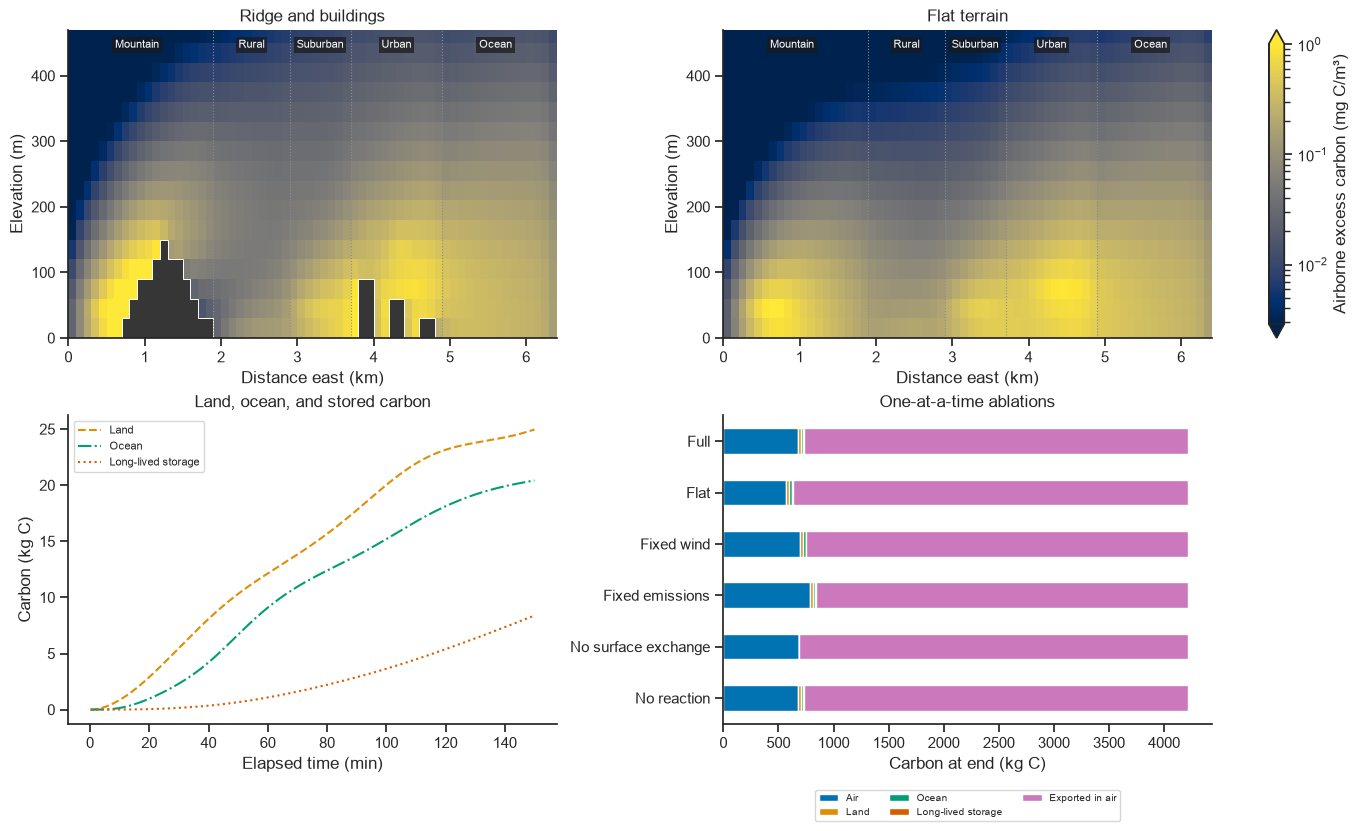

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.2), layout='constrained')
mid, snap_t = ny//2+1, snapshot_times[1]
xe = np.arange(nx+1)*dx/1000
ze = np.arange(nz+1)*dz
concentrations = [snapshots[name][snap_t][0][:, mid].sum(axis=-1)*1e6/cell_volume for name in ['Full', 'Flat']]
vmax = np.percentile(np.concatenate(concentrations).ravel(), 99.5)
norm = LogNorm(vmin=vmax/350, vmax=vmax)
for ax, name, values, floor in zip(axes[0], ['Full', 'Flat'], concentrations, [terrain, flat]):
    colored = ax.pcolormesh(xe, ze, np.ma.masked_less_equal(values.T, 0), cmap='cividis', norm=norm)
    ax.stairs(floor[:, mid]*dz, xe, baseline=0, fill=True, color='0.21', linewidth=0.7)
    for edge in [19, 29, 37, 49]:
        ax.axvline(xe[edge], color='0.55', ls=':', lw=0.8)
    ax.set(xlabel='Distance east (km)', ylabel='Elevation (m)', ylim=(0, 470),
           title='Ridge and buildings' if name == 'Full' else 'Flat terrain')
    for region_name, center in zip(regions, [9, 24, 33, 43, 56]):
        ax.text(xe[center], 447, region_name, ha='center', va='center', fontsize=8,
                color='white', bbox={'facecolor': '0.10', 'alpha': 0.73, 'pad': 2, 'edgecolor': 'none'})
fig.colorbar(colored, ax=axes[0].tolist(), label='Airborne excess carbon (mg C/m³)', extend='both')

budget = {'air_total_kg_c': 'Air', 'land_kg_c': 'Land', 'ocean_kg_c': 'Ocean',
          'stored_kg_c': 'Long-lived storage', 'escaped_kg_c': 'Exported in air'}
full = history.query("scenario == 'Full'")
for i, (key, label) in enumerate(budget.items()):
    if key in ('land_kg_c', 'ocean_kg_c', 'stored_kg_c'):
        axes[1, 0].plot(full['time_s']/60, full[key], color=palette[i],
                        linestyle=['-', '--', '-.', ':', (0, (6, 2, 1, 2))][i], label=label)
axes[1, 0].set(xlabel='Elapsed time (min)', ylabel='Carbon (kg C)', title='Land, ocean, and stored carbon')
axes[1, 0].legend(fontsize=8)

bar = summary[list(budget)].rename(columns=budget)
bar.plot.barh(stacked=True, color=palette[:len(budget)], ax=axes[1, 1], legend=False)
axes[1, 1].invert_yaxis()
axes[1, 1].set(xlabel='Carbon at end (kg C)', ylabel='', title='One-at-a-time ablations')
axes[1, 1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.20), fontsize=7, ncol=3)
sns.despine(fig=fig)
save_figure(fig, out, 'coastal_carbon')
display(fig)
plt.close(fig)

/Users/slmagid/Desktop/MOCS/pdp_gaussian_plume_ca/c_coast/src/shared/common.py:44: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig(output / f'{name}.png', dpi=160, bbox_inches='tight', facecolor='white')
/Users/slmagid/Desktop/MOCS/pdp_gaussian_plume_ca/c_coast/src/shared/common.py:45: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig(output / f'{name}.pdf', bbox_inches='tight', facecolor='white')
/Users/slmagid/miniforge3/envs/research313/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


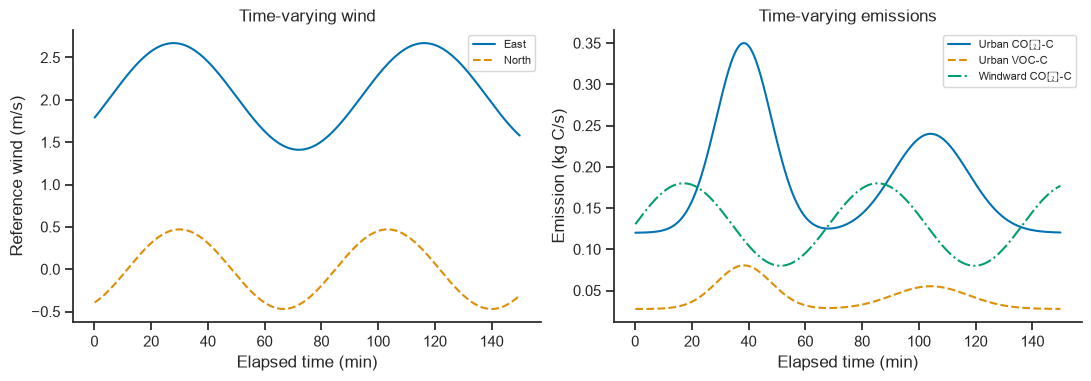

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10.8, 3.7), layout='constrained')
for key, style, label in [('wind_u_m_s', '-', 'East'), ('wind_v_m_s', '--', 'North')]:
    ax[0].plot(forcing['time_s']/60, forcing[key], style, label=label)
for key, style, label in [('urban_co2_kg_c_s', '-', 'Urban CO₂-C'), ('urban_voc_kg_c_s', '--', 'Urban VOC-C'),
                          ('windward_co2_kg_c_s', '-.', 'Windward CO₂-C')]:
    ax[1].plot(forcing['time_s']/60, forcing[key], style, label=label)
for panel in ax:
    panel.set_xlabel('Elapsed time (min)')
    panel.legend(fontsize=8)
ax[0].set(ylabel='Reference wind (m/s)', title='Time-varying wind')
ax[1].set(ylabel='Emission (kg C/s)', title='Time-varying emissions')
sns.despine(fig=fig)
save_figure(fig, out, 'coastal_forcing')
display(fig)
plt.close(fig)